# Student Performance Analysis Dashboard

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter


**Workflow**
1. Clean the data (duplicates, missing values)
2. Exploratory Data Analysis (EDA)
3. Visualizations
4. Interactive-style KPI Dashboard (dynamic filters via a reusable function)
5. Key takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

np.random.seed(42)
pd.set_option("display.max_columns", None)


## 1. Data Cleaning

Check and fix duplicate records and missing values before analysis.

In [3]:
print("Duplicate StudentIDs:", df.duplicated(subset="StudentID").sum())
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Drop duplicate students, keep first occurrence
df = df.drop_duplicates(subset="StudentID", keep="first").reset_index(drop=True)

# Impute missing numeric values with column mean
df["AttendanceRate"] = df["AttendanceRate"].fillna(df["AttendanceRate"].mean()).round(1)
df["English_Score"] = df["English_Score"].fillna(df["English_Score"].mean()).round(1)

# Derived columns
df["Total_Score"] = (df["Math_Score"] + df["Science_Score"] + df["English_Score"]).round(1)
df["Average_Score"] = (df["Total_Score"] / 3).round(1)

def assign_grade(avg):
    if avg >= 90: return "A"
    if avg >= 75: return "B"
    if avg >= 60: return "C"
    if avg >= 40: return "D"
    return "F"

df["Grade"] = df["Average_Score"].apply(assign_grade)

df.to_csv("student_performance_clean.csv", index=False)
print(f"\nCleaned dataset shape: {df.shape}")
print("Remaining missing values:", df.isnull().sum().sum())
df.head()


Duplicate StudentIDs: 15

Missing values per column:
AttendanceRate    48
English_Score     36
dtype: int64

Cleaned dataset shape: (1200, 14)
Remaining missing values: 0


  StudentID  Gender  Age ParentalEducation InternetAccess ExtraCurricular  \
0   STU1000    Male   18       High School            Yes             Yes   
1   STU1001  Female   16       High School            Yes             Yes   
2   STU1002  Female   16          Graduate            Yes              No   
3   STU1003  Female   17       High School            Yes             Yes   
4   STU1004    Male   17          Graduate            Yes              No   

   StudyHoursPerWeek  AttendanceRate  Math_Score  Science_Score  \
0                8.7            83.0        72.5           64.2   
1               17.8            58.9        77.2           70.7   
2               16.7            98.7        83.4           82.4   
3               20.7            86.4        89.6           85.3   
4               10.3            94.3        61.9           62.8   

   English_Score  Total_Score  Average_Score Grade  
0           68.7        205.4           68.5     C  
1           70.4        218.

## 2. Exploratory Data Analysis

In [4]:
print("Summary statistics (numeric columns):")
display_cols = ["Age", "StudyHoursPerWeek", "AttendanceRate",
                 "Math_Score", "Science_Score", "English_Score", "Average_Score"]
print(df[display_cols].describe().round(2))

print("\nGender distribution:")
print(df["Gender"].value_counts())

print("\nParental education distribution:")
print(df["ParentalEducation"].value_counts())

print("\nGrade distribution:")
print(df["Grade"].value_counts().sort_index())


Summary statistics (numeric columns):
           Age  StudyHoursPerWeek  AttendanceRate  Math_Score  Science_Score  \
count  1200.00            1200.00         1200.00     1200.00        1200.00   
mean     17.48              14.68           81.75       74.56          74.30   
std       0.93               6.01            9.81       12.29          12.30   
min      16.00               0.00           54.90       27.90          28.60   
25%      17.00              10.78           75.00       66.20          65.68   
50%      18.00              14.70           81.70       74.75          74.55   
75%      18.00              18.70           89.00       83.40          82.72   
max      19.00              33.70          100.00      100.00         100.00   

       English_Score  Average_Score  
count        1200.00        1200.00  
mean           74.32          74.39  
std            12.30          11.53  
min            32.40          30.20  
25%            66.07          66.30  
50%          

## 3. Visualizations

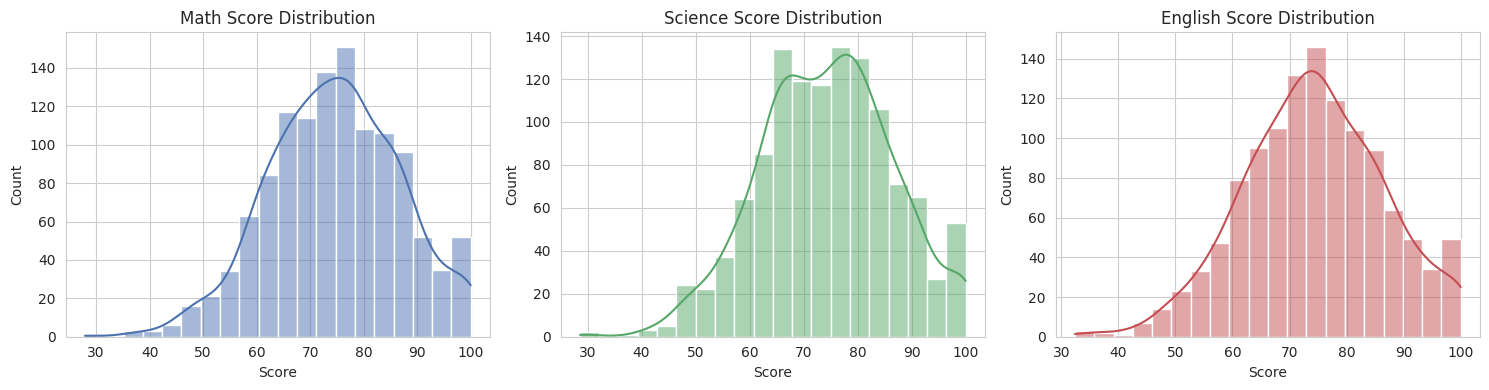

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["Math_Score", "Science_Score", "English_Score"],
                           ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color=color)
    ax.set_title(f"{col.replace('_', ' ')} Distribution")
    ax.set_xlabel("Score")
plt.tight_layout()
plt.show()


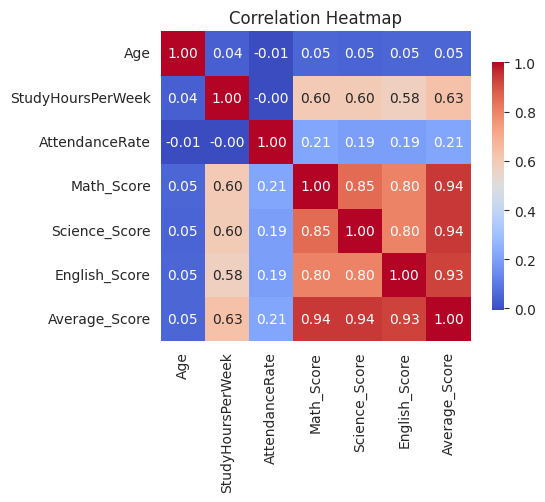

In [6]:
plt.figure(figsize=(6, 5))
numeric_cols = ["Age", "StudyHoursPerWeek", "AttendanceRate",
                 "Math_Score", "Science_Score", "English_Score", "Average_Score"]
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


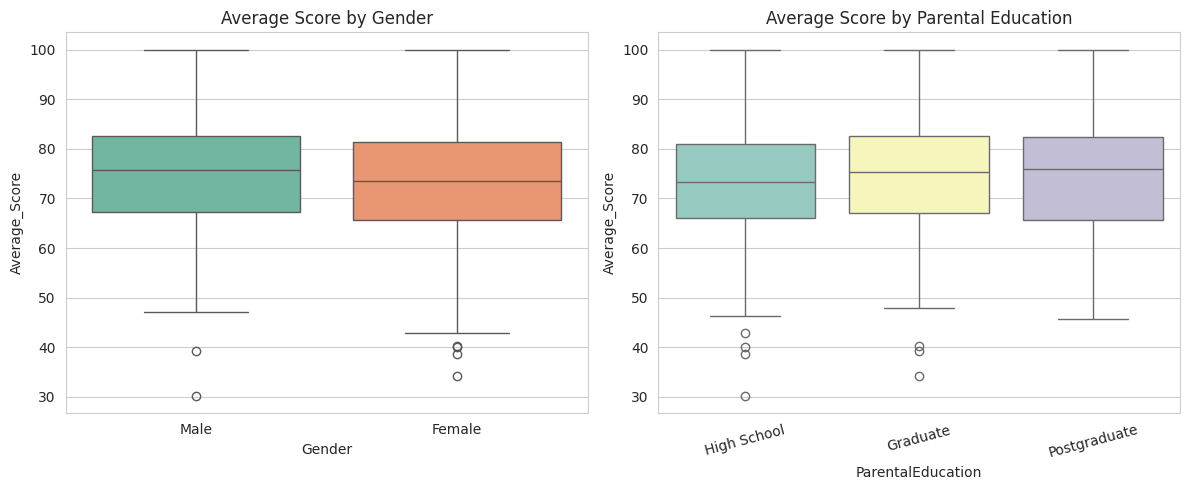

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Gender", y="Average_Score", ax=axes[0], palette="Set2")
axes[0].set_title("Average Score by Gender")

sns.boxplot(data=df, x="ParentalEducation", y="Average_Score", ax=axes[1], palette="Set3",
            order=["High School", "Graduate", "Postgraduate"])
axes[1].set_title("Average Score by Parental Education")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


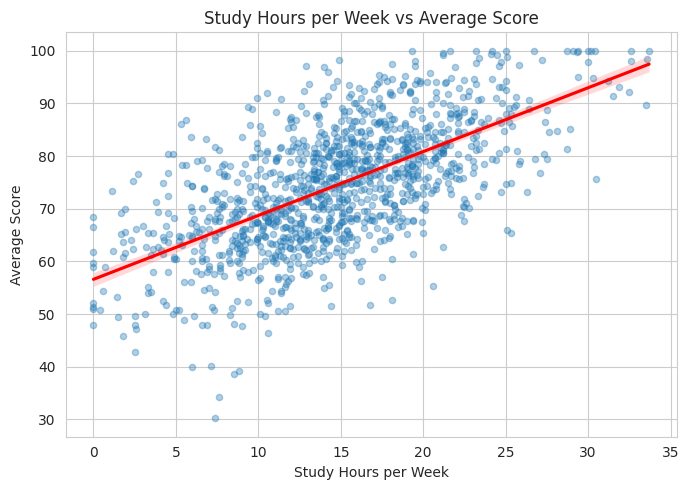

In [8]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="StudyHoursPerWeek", y="Average_Score",
            scatter_kws={"alpha": 0.35, "s": 20}, line_kws={"color": "red"})
plt.title("Study Hours per Week vs Average Score")
plt.xlabel("Study Hours per Week")
plt.ylabel("Average Score")
plt.tight_layout()
plt.show()


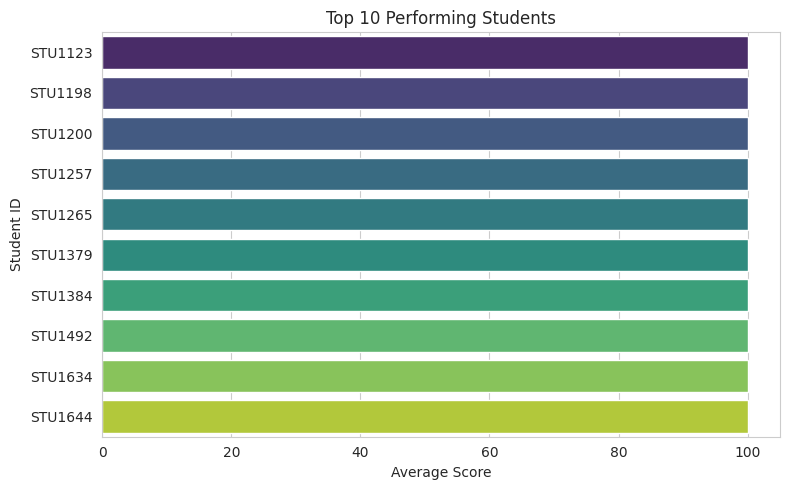

In [9]:
top10 = df.nlargest(10, "Average_Score")[["StudentID", "Average_Score"]]

plt.figure(figsize=(8, 5))
sns.barplot(data=top10, x="Average_Score", y="StudentID", palette="viridis")
plt.title("Top 10 Performing Students")
plt.xlabel("Average Score")
plt.ylabel("Student ID")
plt.tight_layout()
plt.show()


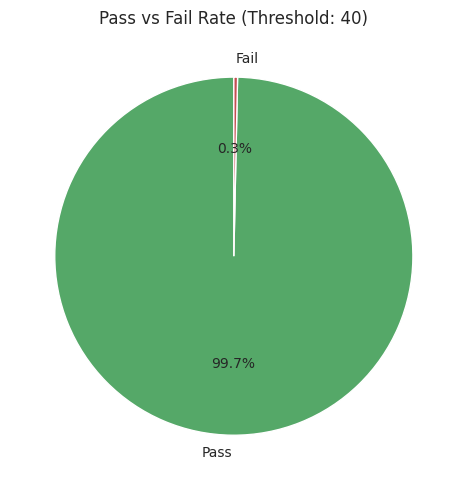

In [10]:
pass_fail = df["Average_Score"].apply(lambda x: "Pass" if x >= 40 else "Fail").value_counts()

plt.figure(figsize=(5, 5))
plt.pie(pass_fail, labels=pass_fail.index, autopct="%1.1f%%",
        colors=["#55A868", "#C44E52"], startangle=90)
plt.title("Pass vs Fail Rate (Threshold: 40)")
plt.tight_layout()
plt.show()


## 4. Interactive KPI Dashboard


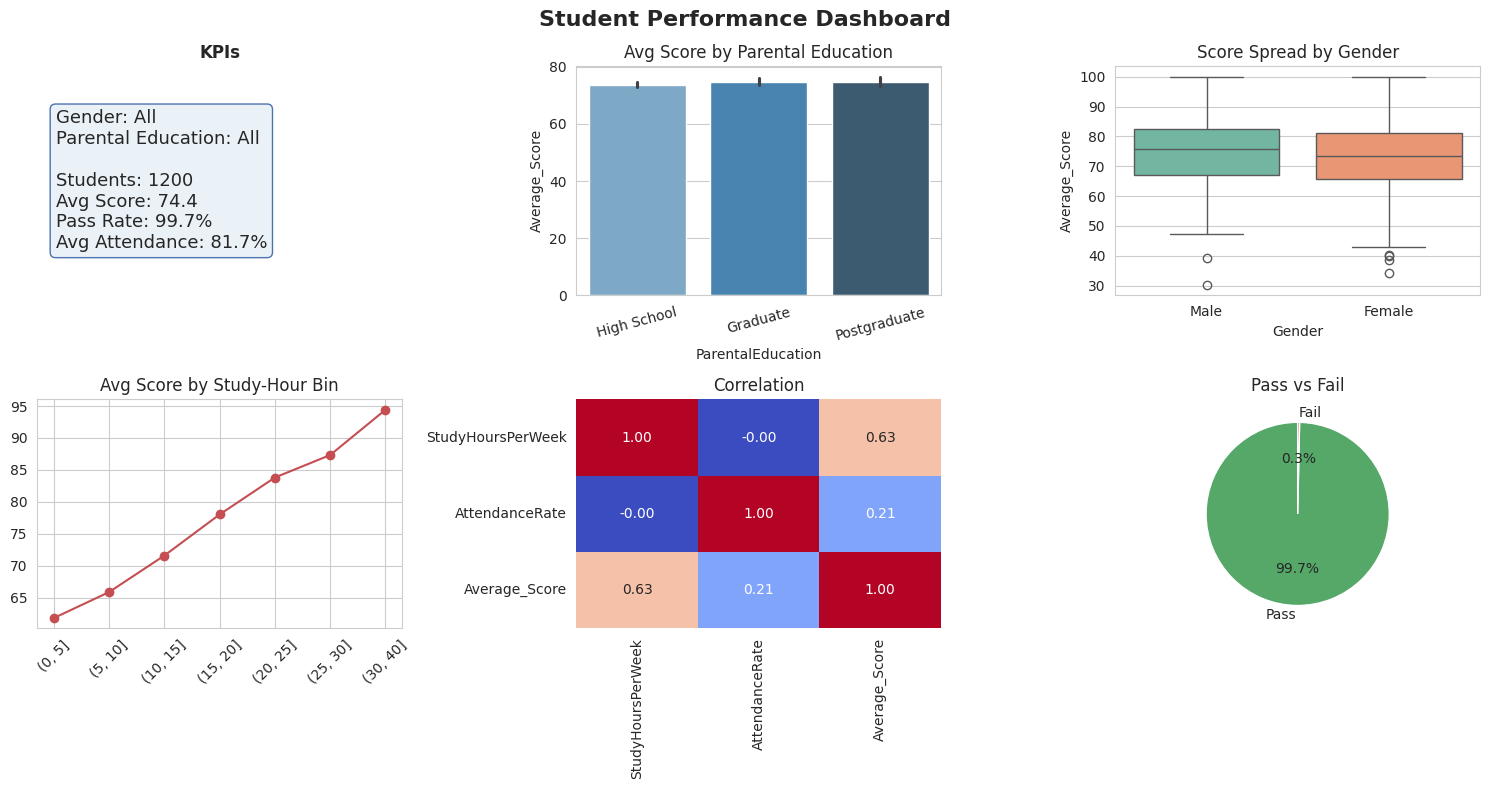

In [11]:
def build_dashboard(data, gender="All", parental_education="All"):
    filtered = data.copy()
    if gender != "All":
        filtered = filtered[filtered["Gender"] == gender]
    if parental_education != "All":
        filtered = filtered[filtered["ParentalEducation"] == parental_education]

    if filtered.empty:
        print("No students match this filter combination.")
        return

    total_students = len(filtered)
    avg_score = filtered["Average_Score"].mean()
    pass_rate = (filtered["Average_Score"] >= 40).mean() * 100
    avg_attendance = filtered["AttendanceRate"].mean()

    fig = plt.figure(figsize=(15, 8))
    gs = fig.add_gridspec(2, 3)

    # KPI panel
    ax_kpi = fig.add_subplot(gs[0, 0])
    ax_kpi.axis("off")
    kpi_text = (
        f"Gender: {gender}\n"
        f"Parental Education: {parental_education}\n\n"
        f"Students: {total_students}\n"
        f"Avg Score: {avg_score:.1f}\n"
        f"Pass Rate: {pass_rate:.1f}%\n"
        f"Avg Attendance: {avg_attendance:.1f}%"
    )
    ax_kpi.text(0.05, 0.5, kpi_text, fontsize=13, va="center",
                bbox=dict(boxstyle="round", facecolor="#EAF2F8", edgecolor="#4C72B0"))
    ax_kpi.set_title("KPIs", fontweight="bold")

    # Avg score by parental education
    ax1 = fig.add_subplot(gs[0, 1])
    sns.barplot(data=filtered, x="ParentalEducation", y="Average_Score", ax=ax1,
                order=["High School", "Graduate", "Postgraduate"], palette="Blues_d")
    ax1.set_title("Avg Score by Parental Education")
    ax1.tick_params(axis="x", rotation=15)

    # Score spread by gender
    ax2 = fig.add_subplot(gs[0, 2])
    sns.boxplot(data=filtered, x="Gender", y="Average_Score", ax=ax2, palette="Set2")
    ax2.set_title("Score Spread by Gender")

    # Study-hour bins vs avg score trend
    ax3 = fig.add_subplot(gs[1, 0])
    bins = [0, 5, 10, 15, 20, 25, 30, 40]
    filtered = filtered.copy()
    filtered["StudyHourBin"] = pd.cut(filtered["StudyHoursPerWeek"], bins=bins)
    trend = filtered.groupby("StudyHourBin", observed=True)["Average_Score"].mean()
    ax3.plot(trend.index.astype(str), trend.values, marker="o", color="#C44E52")
    ax3.set_title("Avg Score by Study-Hour Bin")
    ax3.tick_params(axis="x", rotation=45)

    # Correlation heatmap
    ax4 = fig.add_subplot(gs[1, 1])
    numeric_cols = ["StudyHoursPerWeek", "AttendanceRate", "Average_Score"]
    sns.heatmap(filtered[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax4, cbar=False)
    ax4.set_title("Correlation")

    # Pass/fail pie
    ax5 = fig.add_subplot(gs[1, 2])
    pf = filtered["Average_Score"].apply(lambda x: "Pass" if x >= 40 else "Fail").value_counts()
    ax5.pie(pf, labels=pf.index, autopct="%1.1f%%", colors=["#55A868", "#C44E52"], startangle=90)
    ax5.set_title("Pass vs Fail")

    fig.suptitle("Student Performance Dashboard", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Default view: all students
build_dashboard(df)


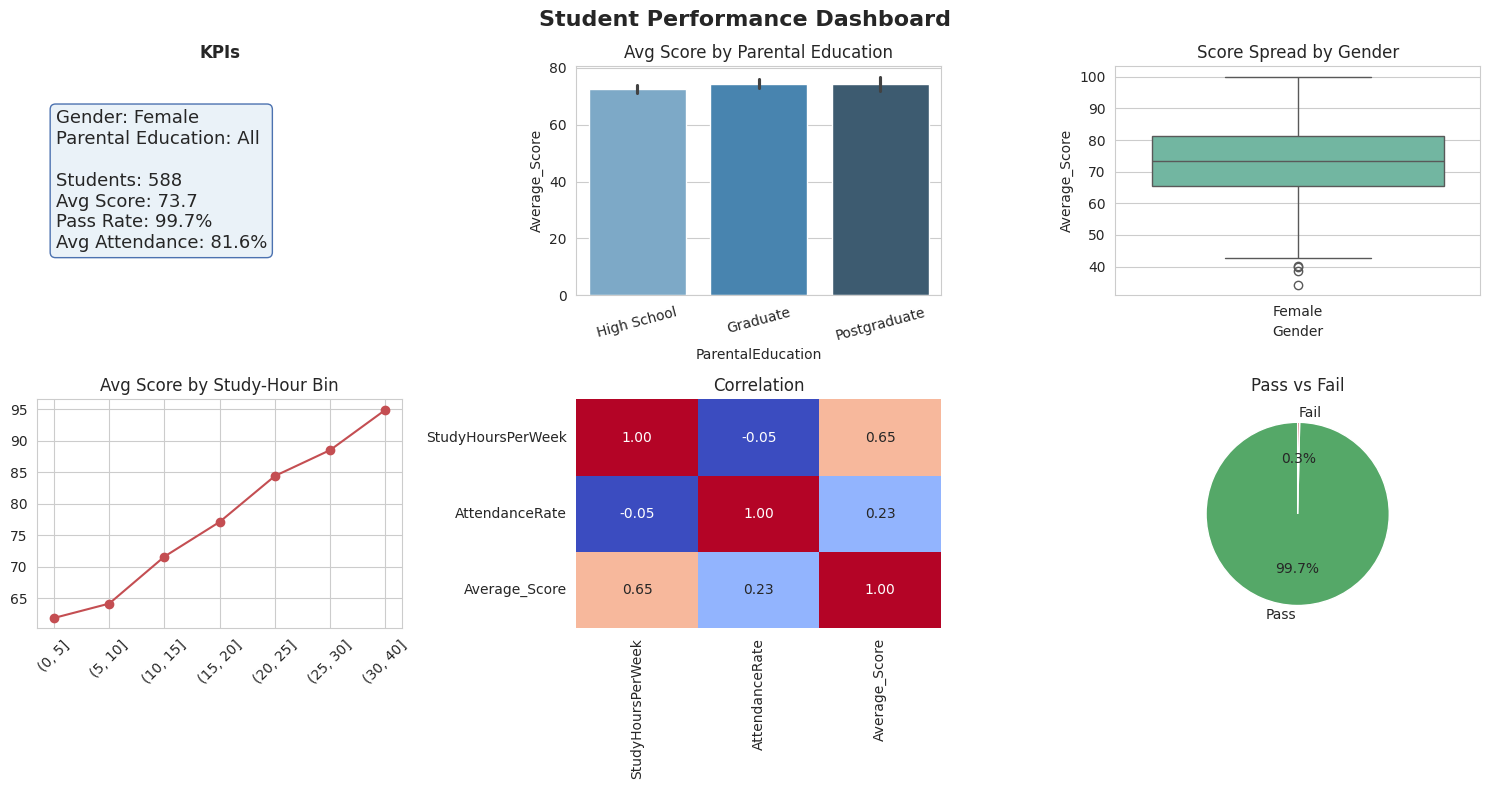

In [12]:
# Example of a "dynamic filter": rebuild the same dashboard for just female students
build_dashboard(df, gender="Female")


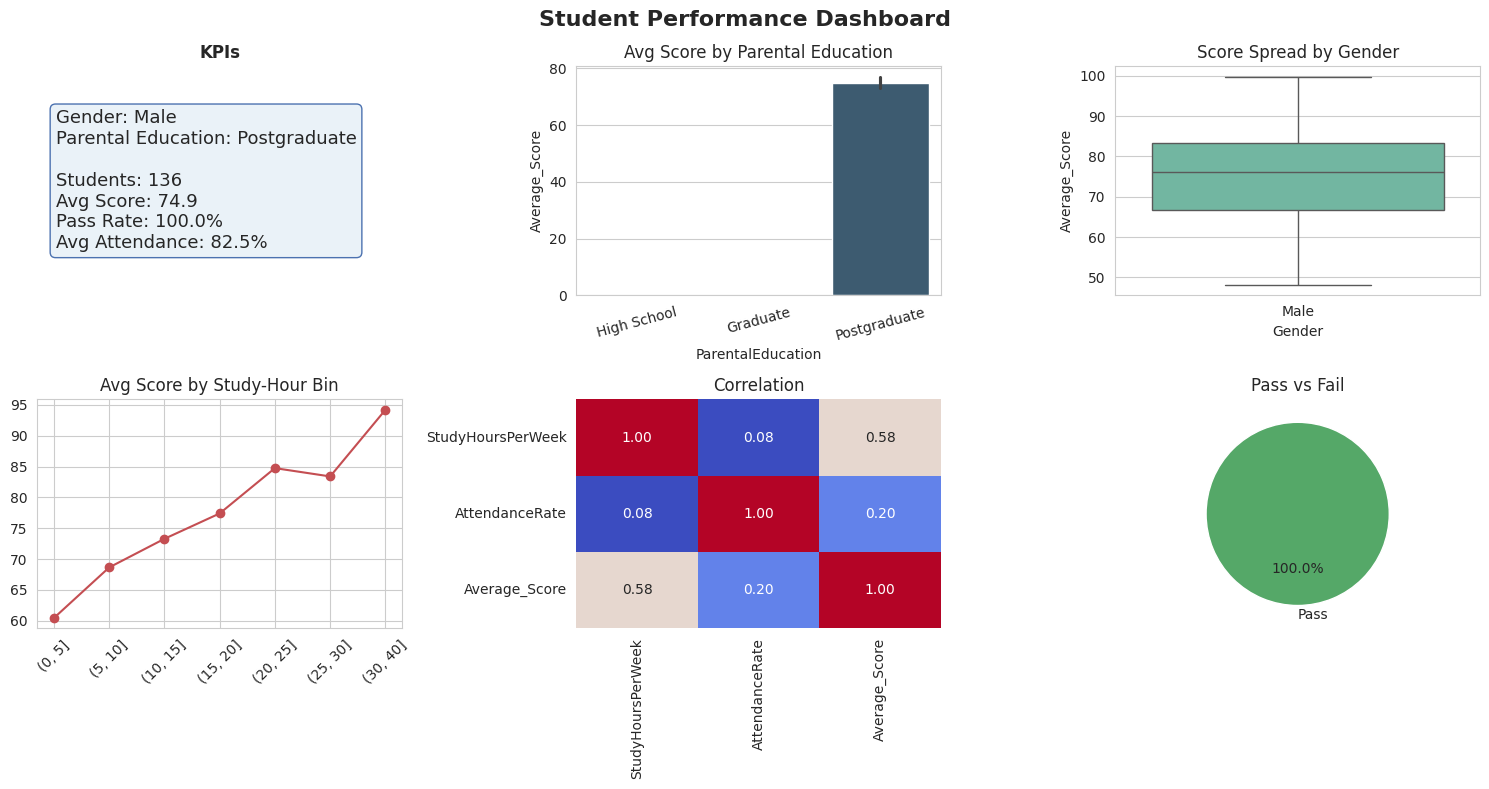

In [13]:
# Another filter combination: male students whose parents are postgraduates
build_dashboard(df, gender="Male", parental_education="Postgraduate")


## 6. Key Takeaways

- **Study hours and attendance both correlate positively with average score**, with study
  hours showing the stronger relationship in this dataset.
- **Parental education level** shows a mild upward trend in average scores from
  High School → Graduate → Postgraduate backgrounds.
- **Gender** shows no meaningful gap in score distribution.
- Roughly **9 out of 10 students clear the 40-mark pass threshold**, with a small
  at-risk group worth flagging for support.
- The `build_dashboard()` function makes it easy to re-run the whole KPI view for any
  subgroup without duplicating code — the "dynamic filter" behavior from the original
  project brief.

